In [2]:
# Carga las librerías y mide cuánto tarda TensorFlow en cargar dentro del notebook.
import time

t = time.time()
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

print("TensorFlow:", tf.__version__, "| tardó", round(time.time() - t), "segundos")

TensorFlow: 2.21.0 | tardó 46 segundos


In [3]:
# Define las rutas y carga los datos preparados en el notebook 04: imágenes, etiquetas y pesos por clase.
t = time.time()

PROYECTO = Path("..")
DATOS = PROYECTO / "Datos"
RESULTADOS = PROYECTO / "Resultados"
GRAFICOS = PROYECTO / "Graficos"
MODELOS = PROYECTO / "Modelos"

EMOCIONES = ["Felicidad", "Neutral", "Tristeza", "Sorpresa", "Asco", "Enojo", "Miedo"]

# Semilla fija para que los resultados sean reproducibles
keras.utils.set_random_seed(42)

X_entrenamiento = np.load(DATOS / "X_entrenamiento.npy")
y_entrenamiento = np.load(DATOS / "y_entrenamiento.npy")
X_validacion = np.load(DATOS / "X_validacion.npy")
y_validacion = np.load(DATOS / "y_validacion.npy")
X_prueba = np.load(DATOS / "X_prueba.npy")
y_prueba = np.load(DATOS / "y_prueba.npy")
pesos = np.load(DATOS / "pesos_clase.npy")

print("Entrenamiento:", X_entrenamiento.shape, "| Validación:", X_validacion.shape, "| Prueba:", X_prueba.shape)
print("Pesos por clase:", pesos.round(2))
print("Tardó", round(time.time() - t), "segundos")

Entrenamiento: (10421, 100, 100, 3) | Validación: (1840, 100, 100, 3) | Prueba: (3065, 100, 100, 3)
Pesos por clase: [0.37 0.7  0.88 1.36 2.44 2.49 6.23]
Tardó 1 segundos


In [4]:
# Define la red neuronal convolucional
modelo = keras.Sequential([
    keras.Input(shape=(100, 100, 3)),
    keras.layers.Rescaling(1 / 255),

    keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(128, 3, activation="relu", padding="same"),
    keras.layers.MaxPooling2D(),

    keras.layers.Flatten(),
    keras.layers.Dropout(0.4),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(7, activation="softmax"),
])

modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 100, 100, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 25, 25, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,453,575 (9.36 MB)

 Trainable params: 2,453,575 (9.36 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Entrena la red con los pesos por clase y la validación; se detiene sola cuando deja de mejorar.
pesos_clase = {numero: peso for numero, peso in enumerate(pesos)}

parada_temprana = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

t = time.time()
historial = modelo.fit(
    X_entrenamiento, y_entrenamiento,
    validation_data=(X_validacion, y_validacion),
    epochs=25,
    batch_size=64,
    class_weight=pesos_clase,
    callbacks=[parada_temprana],
)
print("Entrenamiento terminado en", round((time.time() - t) / 60, 1), "minutos")

Epoch 1/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 38s 226ms/step - accuracy: 0.2823 - loss: 1.7780 - val_accuracy: 0.4630 - val_loss: 1.4185
Epoch 2/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 39s 237ms/step - accuracy: 0.5428 - loss: 1.3415 - val_accuracy: 0.5913 - val_loss: 1.1015
Epoch 3/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 43s 266ms/step - accuracy: 0.6218 - loss: 1.1068 - val_accuracy: 0.6179 - val_loss: 1.0362
Epoch 4/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 45s 274ms/step - accuracy: 0.6663 - loss: 0.9663 - val_accuracy: 0.6332 - val_loss: 1.0196
Epoch 5/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 44s 268ms/step - accuracy: 0.6966 - loss: 0.8483 - val_accuracy: 0.6755 - val_loss: 0.9448
Epoch 6/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 48s 292ms/step - accuracy: 0.7252 - loss: 0.7595 - val_accuracy: 0.6989 - val_loss: 0.8856
Epoch 7/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 43s 265ms/step - accuracy: 0.7482 - loss: 0.6688 - val_accuracy: 0.7174 - val_loss: 0.8895
Epoch 8/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 43s 265ms/step - accuracy: 0.7771 - loss: 0

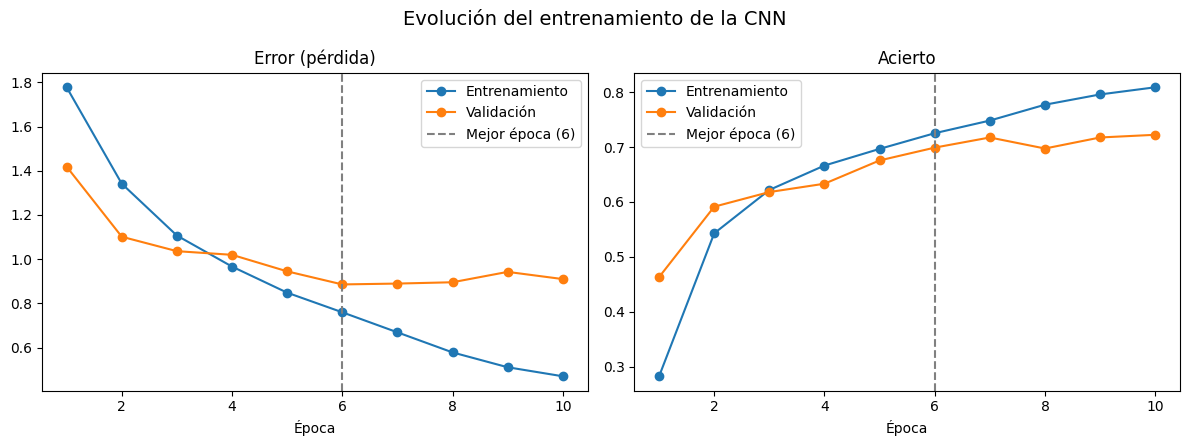

Modelo guardado en ..\Modelos\cnn_emociones.keras


In [6]:
# Grafica el error y el acierto de cada época y guarda el modelo entrenado para no perderlo.
h = historial.history
epocas = range(1, len(h["loss"]) + 1)
mejor_epoca = int(np.argmin(h["val_loss"])) + 1

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for eje, (metrica, titulo) in zip(ejes, [("loss", "Error (pérdida)"), ("accuracy", "Acierto")]):
    eje.plot(epocas, h[metrica], marker="o", label="Entrenamiento")
    eje.plot(epocas, h["val_" + metrica], marker="o", label="Validación")
    eje.axvline(mejor_epoca, color="gray", linestyle="--", label=f"Mejor época ({mejor_epoca})")
    eje.set_title(titulo)
    eje.set_xlabel("Época")
    eje.legend()

plt.suptitle("Evolución del entrenamiento de la CNN", fontsize=14)
plt.tight_layout()
plt.savefig(GRAFICOS / "05_curvas_entrenamiento.png", dpi=150)
plt.show()

modelo.save(MODELOS / "cnn_emociones.keras")
print("Modelo guardado en", MODELOS / "cnn_emociones.keras")

In [7]:
# Evalúa la red con las imágenes de prueba, que nunca usó, y muestra el acierto total y por emoción.
from sklearn.metrics import classification_report

probabilidades = modelo.predict(X_prueba, batch_size=64, verbose=0)
predicciones = probabilidades.argmax(axis=1)

acierto = (predicciones == y_prueba).mean()
print(f"Acierto en prueba: {acierto:.1%} ({(predicciones == y_prueba).sum()} de {len(y_prueba)} imágenes)")
print(f"Referencia (predecir siempre felicidad): {(y_prueba == 0).mean():.1%}")
print()
print(classification_report(y_prueba, predicciones, target_names=EMOCIONES, digits=2))

Acierto en prueba: 70.3% (2156 de 3065 imágenes)
Referencia (predecir siempre felicidad): 38.7%

              precision    recall  f1-score   support

   Felicidad       0.87      0.87      0.87      1185
     Neutral       0.75      0.50      0.60       680
    Tristeza       0.56      0.71      0.63       477
    Sorpresa       0.78      0.72      0.75       329
        Asco       0.29      0.56      0.38       160
       Enojo       0.62      0.59      0.61       160
       Miedo       0.47      0.39      0.43        74

    accuracy                           0.70      3065
   macro avg       0.62      0.62      0.61      3065
weighted avg       0.73      0.70      0.71      3065



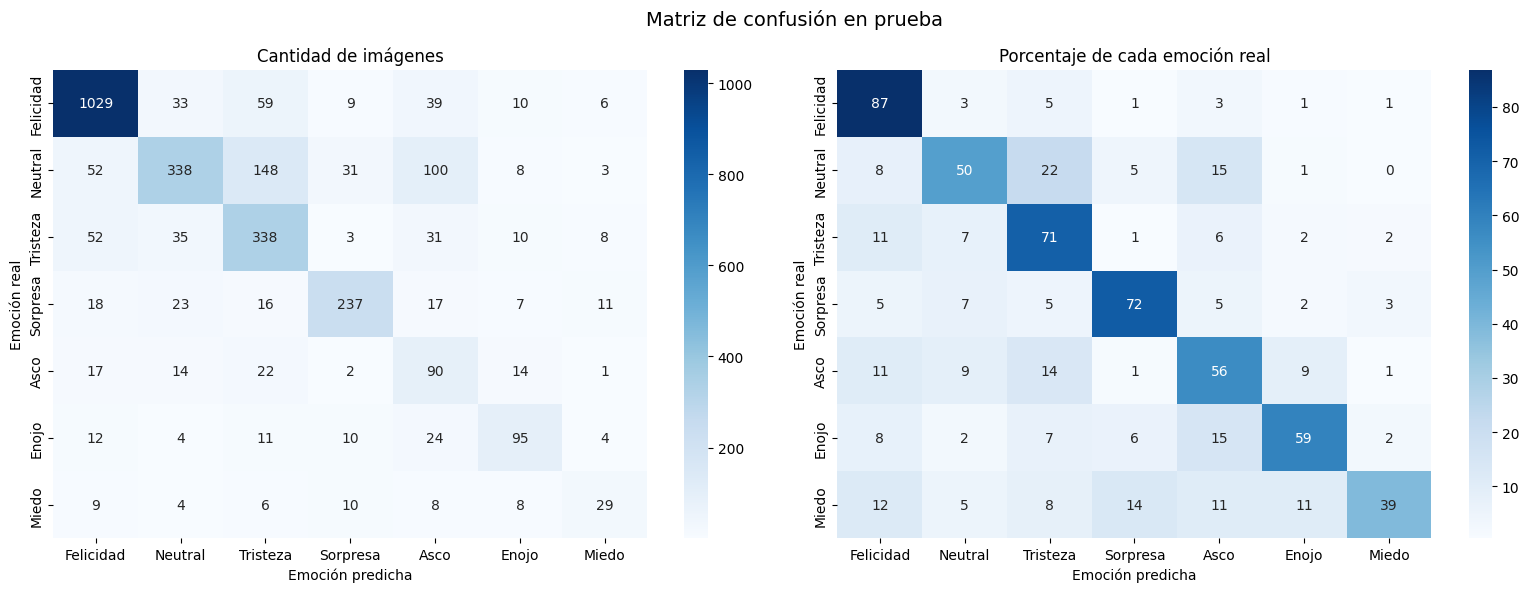

In [8]:
# Cuenta, para cada emoción real, qué emoción predijo la red, y lo dibuja como matriz de colores.
from sklearn.metrics import confusion_matrix
import seaborn as sns

matriz = confusion_matrix(y_prueba, predicciones)
matriz_pct = matriz / matriz.sum(axis=1, keepdims=True) * 100

fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=EMOCIONES, yticklabels=EMOCIONES, ax=ejes[0])
ejes[0].set_title("Cantidad de imágenes")
sns.heatmap(matriz_pct, annot=True, fmt=".0f", cmap="Blues", xticklabels=EMOCIONES, yticklabels=EMOCIONES, ax=ejes[1])
ejes[1].set_title("Porcentaje de cada emoción real")
for eje in ejes:
    eje.set_xlabel("Emoción predicha")
    eje.set_ylabel("Emoción real")

plt.suptitle("Matriz de confusión en prueba", fontsize=14)
plt.tight_layout()
plt.savefig(GRAFICOS / "05_matriz_confusion.png", dpi=150)
plt.show()

In [9]:
# Guarda las predicciones de la red por imagen, las métricas por emoción y la matriz de confusión para analizarlas y llevarlas a Power BI.
from sklearn.metrics import precision_recall_fscore_support

prueba = pd.read_csv(RESULTADOS / "prueba_imagenes.csv")
assert (prueba["etiqueta"].to_numpy() == y_prueba).all(), "El orden de las imágenes no coincide"

prueba["prediccion"] = [EMOCIONES[i] for i in predicciones]
prueba["acierto"] = prueba["prediccion"] == prueba["emocion"]
prueba["confianza"] = probabilidades.max(axis=1).round(3)
prueba.to_csv(RESULTADOS / "predicciones_prueba.csv", index=False, encoding="utf-8-sig")

precision, recall, f1, cantidad = precision_recall_fscore_support(y_prueba, predicciones)
metricas = pd.DataFrame({"emocion": EMOCIONES, "precision": precision.round(3), "recall": recall.round(3),
                         "f1": f1.round(3), "imagenes": cantidad})
metricas.to_csv(RESULTADOS / "metricas_emociones.csv", index=False, encoding="utf-8-sig")

pd.DataFrame(matriz, index=EMOCIONES, columns=EMOCIONES).to_csv(RESULTADOS / "matriz_confusion.csv", encoding="utf-8-sig")

print("Aciertos guardados:", prueba["acierto"].sum(), "de", len(prueba))
metricas

Aciertos guardados: 2156 de 3065


,emocion,precision,recall,f1,imagenes
0,Felicidad,0.865,0.868,0.867,1185
1,Neutral,0.749,0.497,0.598,680
2,Tristeza,0.563,0.709,0.628,477
3,Sorpresa,0.785,0.720,0.751,329
4,Asco,0.291,0.562,0.384,160
5,Enojo,0.625,0.594,0.609,160
6,Miedo,0.468,0.392,0.426,74
